Cohort size across both modalities: 89 patients.
✅ High-legibility figure saved with enlarged publication fonts.


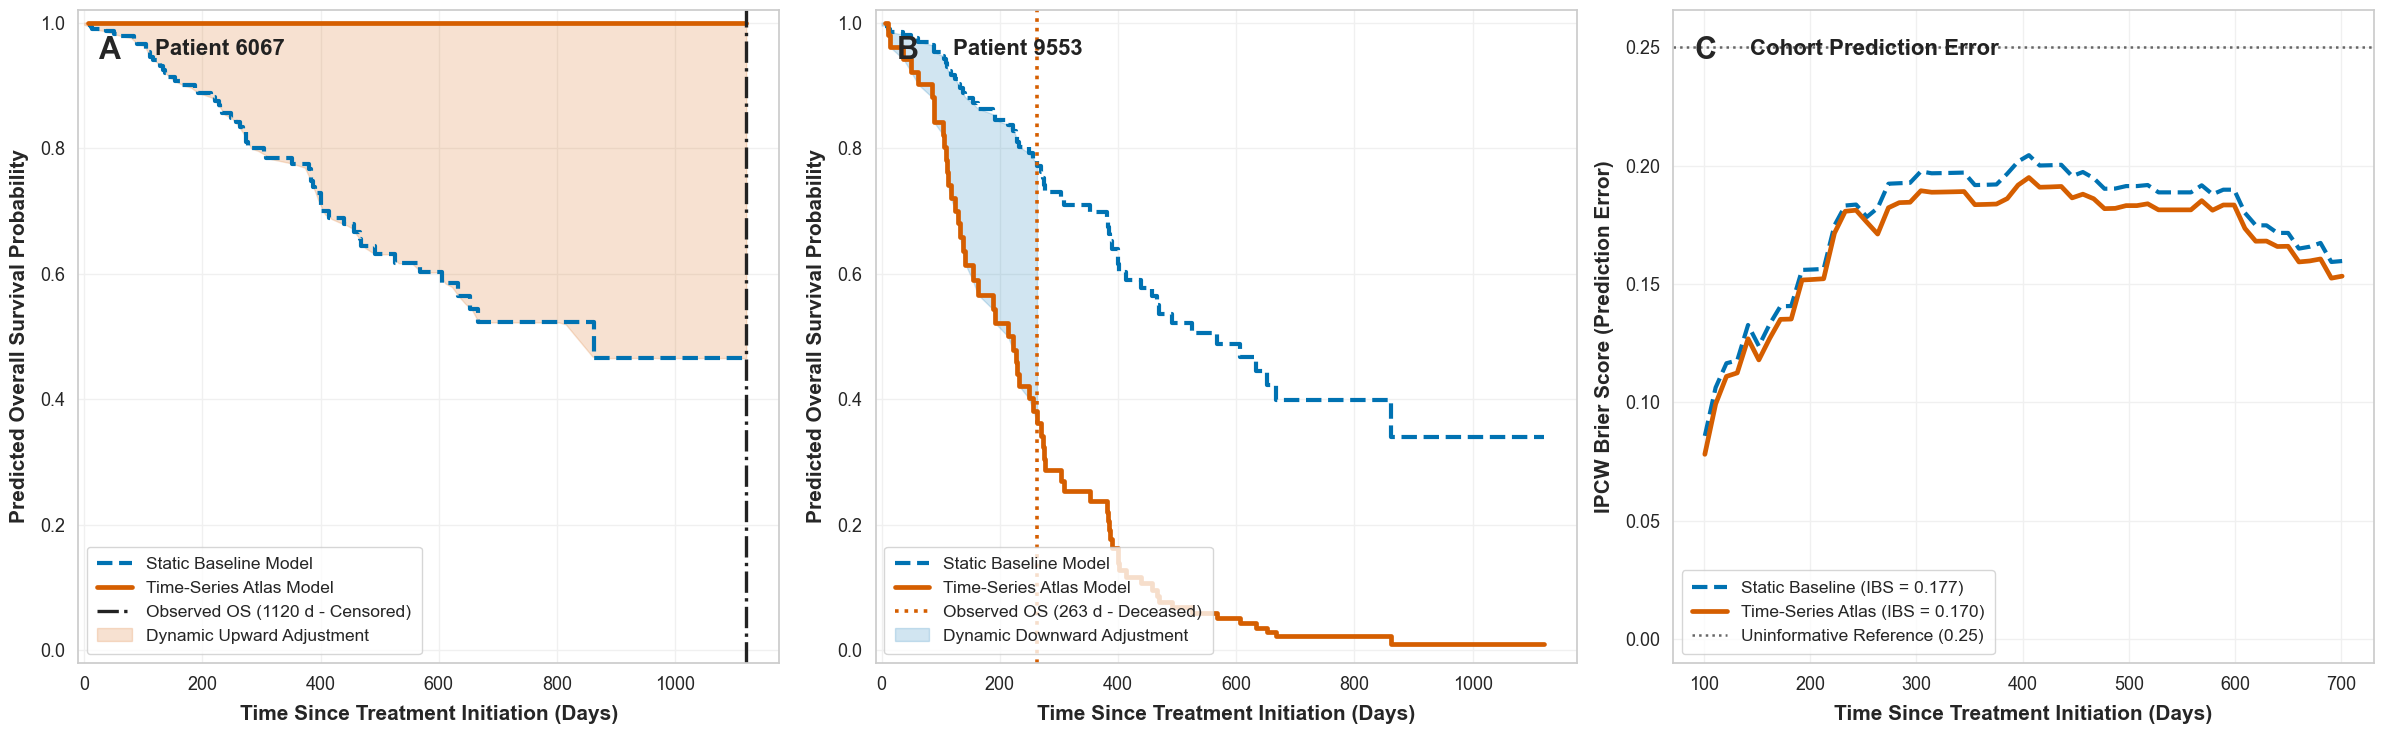

In [55]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from patsy import bs
from lifelines import CoxPHFitter, KaplanMeierFitter
import warnings

warnings.filterwarnings('ignore')

# =====================================================================
# 1. PREPROCESSING
# =====================================================================
times = pd.read_csv("IntermediateResults/Patient_Atlas.csv")
times['Patient_ID'] = times['Patient_ID'].astype(str).str.strip()

merged_time = pd.merge(
    patient_vals,
    times,
    left_on=patient_vals['Study_subject'].astype(str).str.strip(),
    right_on='Patient_ID',
    how='inner'
)

# Numeric conversions
merged['OS_time'] = pd.to_numeric(merged['OS_time'], errors='coerce')
merged['OS_status'] = pd.to_numeric(merged['OS_status'], errors='coerce')
merged_time['OS_time'] = pd.to_numeric(merged_time['OS_time'], errors='coerce')
merged_time['OS_status'] = pd.to_numeric(merged_time['OS_status'], errors='coerce')

# Filter complete cases across both sets
cols_static_raw = ['Study_subject', 'OS_time', 'OS_status', 'coef_weighted', 'pHSC_weighted']
cols_time_raw = [
    'Patient_ID', 'OS_time', 'OS_status', 'Predefined_Coef', 'Predefined_pHSC',
    'Fitted_DrugKill_LSC', 'Fitted_DrugKill_HSC'
]

clean_static = merged.dropna(subset=cols_static_raw).copy()
clean_time = merged_time.dropna(subset=cols_time_raw).copy()

common_ids = set(clean_static['Study_subject'].astype(str).str.strip()).intersection(
    set(clean_time['Patient_ID'].astype(str).str.strip())
)
print(f"Cohort size across both modalities: {len(common_ids)} patients.")

df_static = clean_static[clean_static['Study_subject'].astype(str).str.strip().isin(common_ids)].copy()
df_time = clean_time[clean_time['Patient_ID'].astype(str).str.strip().isin(common_ids)].copy()

df_static = df_static.sort_values('Study_subject').reset_index(drop=True)
df_time = df_time.sort_values('Patient_ID').reset_index(drop=True)

df_static['coef_z'] = (df_static['coef_weighted'] - df_static['coef_weighted'].mean()) / df_static['coef_weighted'].std()
df_static['pHSC_z'] = (df_static['pHSC_weighted'] - df_static['pHSC_weighted'].mean()) / df_static['pHSC_weighted'].std()

df_time['Predefined_Coef_z'] = (df_time['Predefined_Coef'] - df_time['Predefined_Coef'].mean()) / df_time['Predefined_Coef'].std()
df_time['Predefined_pHSC_z'] = (df_time['Predefined_pHSC'] - df_time['Predefined_pHSC'].mean()) / df_time['Predefined_pHSC'].std()
df_time['Fitted_DrugKill_LSC_z'] = (df_time['Fitted_DrugKill_LSC'] - df_time['Fitted_DrugKill_LSC'].mean()) / df_time['Fitted_DrugKill_LSC'].std()
df_time['Fitted_DrugKill_HSC_z'] = (df_time['Fitted_DrugKill_HSC'] - df_time['Fitted_DrugKill_HSC'].mean()) / df_time['Fitted_DrugKill_HSC'].std()

static_cols = ['OS_time', 'OS_status', 'pHSC_z', 'coef_z']
time_cols = [
    'OS_time', 'OS_status', 'Predefined_pHSC_z', 'Predefined_Coef_z',
    'Fitted_DrugKill_LSC_z', 'Fitted_DrugKill_HSC_z'
]

df_static_model = df_static[static_cols].astype(float)
df_time_model = df_time[time_cols].astype(float)

df_static_model.index = df_static['Study_subject'].astype(str).str.strip()
df_time_model.index = df_time['Patient_ID'].astype(str).str.strip()
# =====================================================================
formula_static = "pHSC_z + coef_z"
formula_time = "Predefined_pHSC_z  + Predefined_Coef_z + Fitted_DrugKill_HSC_z + Fitted_DrugKill_LSC_z"

cph_static = CoxPHFitter()
cph_static.fit(df_static_model, duration_col='OS_time', event_col='OS_status', formula=formula_static)

cph_time = CoxPHFitter()
cph_time.fit(df_time_model, duration_col='OS_time', event_col='OS_status', formula=formula_time)

# =====================================================================
# 3. IPCW BRIER SCORE OVER TIME
# =====================================================================
def compute_ipcw_brier_scores(cph_model, df, duration_col, event_col, eval_times):
    t_obs = df[duration_col].values
    e_obs = df[event_col].values
    n = len(df)

    km_cens = KaplanMeierFitter()
    km_cens.fit(t_obs, 1 - e_obs)
    surv_matrix = cph_model.predict_survival_function(df, times=eval_times).values

    brier_scores = []
    for idx, t in enumerate(eval_times):
        s_pred = surv_matrix[idx, :]
        g_at_t = max(km_cens.predict(t), 1e-4)

        ev_before = (t_obs <= t) & (e_obs == 1)
        g_at_ti = np.maximum(km_cens.predict(t_obs[ev_before]), 1e-4)
        term_event = np.sum((s_pred[ev_before] ** 2) / g_at_ti)

        alive_past = t_obs > t
        term_alive = np.sum(((1.0 - s_pred[alive_past]) ** 2) / g_at_t)

        brier_scores.append((term_event + term_alive) / n)

    brier_scores = np.array(brier_scores)
    integrate_trapz = getattr(np, 'trapezoid', getattr(np, 'trapz', None))
    ibs = integrate_trapz(brier_scores, eval_times) / (eval_times[-1] - eval_times[0])
    return brier_scores, ibs

t_min = np.percentile(df_static_model['OS_time'], 10)
t_max = np.percentile(df_static_model['OS_time'], 85)
eval_times = np.linspace(t_min, t_max, 60)

bs_curve_static, ibs_static = compute_ipcw_brier_scores(cph_static, df_static_model, 'OS_time', 'OS_status', eval_times)
bs_curve_time, ibs_time = compute_ipcw_brier_scores(cph_time, df_time_model, 'OS_time', 'OS_status', eval_times)

# =====================================================================
# 4. DIGITAL TWIN CASE IDENTIFICATION
# =====================================================================
surv_static_365 = cph_static.predict_survival_function(df_static_model, times=[365]).T
surv_time_365 = cph_time.predict_survival_function(df_time_model, times=[365]).T

scanner_df = pd.DataFrame(index=df_time_model.index)
scanner_df['OS_time'] = df_time_model['OS_time']
scanner_df['OS_status'] = df_time_model['OS_status']
scanner_df['S_Static_1yr'] = surv_static_365.values
scanner_df['S_Time_1yr'] = surv_time_365.values
scanner_df['Shift_Optimism'] = scanner_df['S_Time_1yr'] - scanner_df['S_Static_1yr']

id_A = scanner_df[scanner_df['OS_time'] > 600].sort_values('Shift_Optimism', ascending=False).index[0]
id_B = scanner_df[
    (scanner_df['OS_time'] >= 60) & (scanner_df['OS_time'] <= 400) & (scanner_df['OS_status'] == 1)
].sort_values('Shift_Optimism', ascending=True).index[0]

# =====================================================================
# 5. GENERATE  FIGURE
# =====================================================================
sns.set_theme(style="whitegrid", rc={"grid.color": "#f0f0f0", "grid.linestyle": "-"})
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['pdf.fonttype'] = 42

# 1 row x 3 columns with added height to balance larger fonts
fig, axes = plt.subplots(1, 3, figsize=(24, 7.5))

# Okabe-Ito Colorblind-Safe Palette
c_static = "#0072B2"      # High-contrast accessible deep blue
c_dynamic = "#D55E00"     # High-contrast accessible vermilion
c_neutral = "#222222"     # Dark charcoal
c_ref = "#666666"         # Benchmark gray

max_time = max(df_static_model['OS_time'].max(), df_time_model['OS_time'].max()) * 1.05

# ----------------- PANEL A: PATIENT 6067 -----------------
ax_a = axes[0]
curve_stat_A = cph_static.predict_survival_function(df_static_model.loc[[id_A]])
curve_time_A = cph_time.predict_survival_function(df_time_model.loc[[id_A]])

ax_a.step(curve_stat_A.index.values, curve_stat_A.iloc[:, 0].values, where='post', 
          color=c_static, linewidth=3.0, linestyle='--', label="Static Baseline Model")
ax_a.step(curve_time_A.index.values, curve_time_A.iloc[:, 0].values, where='post', 
          color=c_dynamic, linewidth=3.4, linestyle='-', label="Time-Series Atlas Model")

os_day_A = df_time_model.loc[id_A, 'OS_time']
os_stat_A = df_time_model.loc[id_A, 'OS_status']
status_A = "Deceased" if os_stat_A == 1 else "Censored"
ax_a.axvline(x=os_day_A, color=c_neutral, linestyle='-.', linewidth=2.4, 
             label=f"Observed OS ({os_day_A:.0f} d - {status_A})")

eval_A = np.linspace(0, min(os_day_A, curve_stat_A.index.max()), 100)
s_sA = np.interp(eval_A, curve_stat_A.index.values, curve_stat_A.iloc[:, 0].values)
s_tA = np.interp(eval_A, curve_time_A.index.values, curve_time_A.iloc[:, 0].values)
ax_a.fill_between(eval_A, s_sA, s_tA, color=c_dynamic, alpha=0.18, label="Dynamic Upward Adjustment")

ax_a.text(0.03, 0.96, "A", transform=ax_a.transAxes, fontsize=22, fontweight='bold', va='top')
ax_a.text(0.11, 0.955, f"Patient {id_A}", transform=ax_a.transAxes, fontsize=16, fontweight='bold', va='top', color=c_neutral)

ax_a.set_xlabel("Time Since Treatment Initiation (Days)", fontsize=15, fontweight='bold', labelpad=8)
ax_a.set_ylabel("Predicted Overall Survival Probability", fontsize=15, fontweight='bold', labelpad=8)
ax_a.set_xlim(-10, max_time)
ax_a.set_ylim(-0.02, 1.02)
ax_a.tick_params(axis='both', labelsize=13)
ax_a.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#cccccc', fontsize=12.5, borderpad=0.6)

# ----------------- PANEL B: PATIENT 9553 -----------------
ax_b = axes[1]
curve_stat_B = cph_static.predict_survival_function(df_static_model.loc[[id_B]])
curve_time_B = cph_time.predict_survival_function(df_time_model.loc[[id_B]])

ax_b.step(curve_stat_B.index.values, curve_stat_B.iloc[:, 0].values, where='post', 
          color=c_static, linewidth=3.0, linestyle='--', label="Static Baseline Model")
ax_b.step(curve_time_B.index.values, curve_time_B.iloc[:, 0].values, where='post', 
          color=c_dynamic, linewidth=3.4, linestyle='-', label="Time-Series Atlas Model")

os_day_B = df_time_model.loc[id_B, 'OS_time']
os_stat_B = df_time_model.loc[id_B, 'OS_status']
status_B = "Deceased" if os_stat_B == 1 else "Censored"
ax_b.axvline(x=os_day_B, color=c_dynamic, linestyle=':', linewidth=2.6, 
             label=f"Observed OS ({os_day_B:.0f} d - {status_B})")

eval_B = np.linspace(0, min(os_day_B, curve_stat_B.index.max()), 100)
s_sB = np.interp(eval_B, curve_stat_B.index.values, curve_stat_B.iloc[:, 0].values)
s_tB = np.interp(eval_B, curve_time_B.index.values, curve_time_B.iloc[:, 0].values)
ax_b.fill_between(eval_B, s_sB, s_tB, color=c_static, alpha=0.18, label="Dynamic Downward Adjustment")

# Enlarged panel letter and title header
ax_b.text(0.03, 0.96, "B", transform=ax_b.transAxes, fontsize=22, fontweight='bold', va='top')
ax_b.text(0.11, 0.955, f"Patient {id_B}", transform=ax_b.transAxes, fontsize=16, fontweight='bold', va='top', color=c_neutral)

ax_b.set_xlabel("Time Since Treatment Initiation (Days)", fontsize=15, fontweight='bold', labelpad=8)
ax_b.set_ylabel("Predicted Overall Survival Probability", fontsize=15, fontweight='bold', labelpad=8)
ax_b.set_xlim(-10, max_time)
ax_b.set_ylim(-0.02, 1.02)
ax_b.tick_params(axis='both', labelsize=13)
ax_b.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#cccccc', fontsize=12.5, borderpad=0.6)

# ----------------- PANEL C: CONTINUOUS IPCW BRIER SCORE -----------------
ax_c = axes[2]
ax_c.plot(eval_times, bs_curve_static, color=c_static, linewidth=3.0, linestyle='--', 
          label=f"Static Baseline (IBS = {ibs_static:.3f})")
ax_c.plot(eval_times, bs_curve_time, color=c_dynamic, linewidth=3.4, linestyle='-', 
          label=f"Time-Series Atlas (IBS = {ibs_time:.3f})")
ax_c.axhline(0.25, linestyle=':', color=c_ref, linewidth=1.8, label="Uninformative Reference (0.25)")

# Enlarged panel letter and title header
ax_c.text(0.03, 0.96, "C", transform=ax_c.transAxes, fontsize=22, fontweight='bold', va='top')
ax_c.text(0.11, 0.955, "Cohort Prediction Error", transform=ax_c.transAxes, fontsize=16, fontweight='bold', va='top', color=c_neutral)

ax_c.set_xlabel("Time Since Treatment Initiation (Days)", fontsize=15, fontweight='bold', labelpad=8)
ax_c.set_ylabel("IPCW Brier Score (Prediction Error)", fontsize=15, fontweight='bold', labelpad=8)
ax_c.set_ylim(-0.01, max(max(bs_curve_static), max(bs_curve_time)) * 1.3)
ax_c.tick_params(axis='both', labelsize=13)
ax_c.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#cccccc', fontsize=12.5, borderpad=0.6)

plt.tight_layout()
os.makedirs("Figures", exist_ok=True)
plt.savefig('Figures/Figure_Digital_Twin_1x3.pdf', dpi=300, bbox_inches='tight')
plt.savefig('Figures/Figure_Digital_Twin_1x3.png', dpi=300, bbox_inches='tight')
print("Figure saved ")
plt.show()